## from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))
display(HTML("<style>.output_result { max-width:100% !important; }</style>"))

In [ ]:
## To check later
#https://stackoverflow.com/questions/64220211/using-keras-tuner-for-time-series-split

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pandas import DataFrame, concat
import os,itertools,pickle,csv,random
from datetime import datetime

import xgboost as xgb
import tensorflow as tf

#Below codes are to enable reproducability
seed_value = 42   # Set the seed for reproducibility
random.seed(seed_value)  # Set the seed for Python's random number generators
np.random.seed(seed_value)  # Set the seed for NumPy's random number generators
tf.random.set_seed(seed_value)   # Set the seed for TensorFlow's random number generator

# Restrict TensorFlow to use only one thread for intra-op parallelism
tf.config.threading.set_intra_op_parallelism_threads(1)

# Restrict TensorFlow to use only one thread for inter-op parallelism
tf.config.threading.set_inter_op_parallelism_threads(1)

# Set environment variable to enable deterministic operations in TensorFlow
os.environ['TF_DETERMINISTIC_OPS'] = '1'

# Enable experimental determinism in TensorFlow operations
tf.config.experimental.enable_op_determinism()

#Logging setting for tf
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Ignore TensorFlow INFO and WARNING messages


### Project constants

In [12]:
ROUTE = 'b_PIE'
ROUTE_LIST = [ 'b_PIE']

PREPROCESSING_DIR ='b_PIE_preprocessing_models'
ENCODER_FILE =  os.path.join(PREPROCESSING_DIR, 'encoder.pkl') 
SCALAR_X_FILE = os.path.join(PREPROCESSING_DIR, 'scaler_X.pkl')  
SCALAR_Y_FILE = os.path.join(PREPROCESSING_DIR, 'scaler_Y.pkl')  

COLS_TO_OHE = ['X5_Day_name','route_order','hour']

COLS_NOT_NEEDED = ['Route', 'Camera_id', 'X1_Vehicles_no_filter', 'X3_bbratio_no_filter',
                'X6_Vehicles_no_filter_cam_idPlus1', 'X8_bbratio_no_filter_cam_idPlus1',
                'X10_Vehicles_no_filter_cam_idMinus1','X12_bbratio_no_filter_cam_idMinus1',
                'X5_Day_name_Sunday','route_order_1','hour_4','minute','X14_Month']

##https://stackoverflow.com/questions/28538536/deleting-multiple-columns-based-on-column-names-in-pandas
ORG_COLS_TO_DROP = COLS_TO_OHE  + COLS_NOT_NEEDED


HYPER_PARAM_DIR = 'b_PIE_hyperparam'
BEST_MODELS_DIR = 'b_PIE_best_models'

BEST_MODELS_PARAM_FILE = 'model_params.csv'
MODELS_RMSE_FILE ="model_rmse.csv"

#File to store previous Speed lags for our test data
TEST_SPEED_RESULT_FILE=  os.path.join(BEST_MODELS_DIR, ROUTE+ "_june_speed_result.csv")

#File to store previous Speed lags for our test data
INITIAL_SPEED_FILE_FOR_TEST_LAGS =  os.path.join(BEST_MODELS_DIR, ROUTE +"_lagSpeedinit.csv")


MODEL_NAMES_ORG = {'lstm_m1': 'lstm_m1.h5', 'lstm_m2': 'lstm_m2.h5','lstm_m3': 'lstm_m3.h5',
              'lstm_m4': 'lstm_m4.h5',  'xgb_m1': 'xbg_m1.pkl', 'xgb_m2' : 'xgb_m2.pkl',
              'xgb_m3': 'xgb_m3.pkl', 'xgb_m4': 'xgb_m4.pkl', 'svr_m1':'svr_m1.pkl',
               'svr_m2':'svr_m2.pkl','svr_m3':'svr_m3.pkl', 'svr_m4':'svr_m4.pkl' }

MODEL_NAMES = {'lstm_m1': 'lstm_m1.h5', 'lstm_m2': 'lstm_m2.h5','lstm_m3': 'lstm_m3.h5',
              'lstm_m4': 'lstm_m4.h5',  'xgb_m1': 'xbg_m1.pkl', 'xgb_m2' : 'xgb_m2.pkl',
              'xgb_m3': 'xgb_m3.pkl', 'xgb_m4': 'xgb_m4.pkl', 'svr_m1':'svr_m1.pkl',
               'svr_m2':'svr_m2.pkl','svr_m3':'svr_m3.pkl', 'svr_m4':'svr_m4.pkl',
               'rf_m1' : 'rf_m1.pkl','rf_m2' : 'rf_m2.pkl','rf_m3' : 'rf_m3.pkl','rf_m4' : 'rf_m4.pkl',
              'lstm_m2_1': 'lstm_m2_1.h5','lstm_m2_3': 'lstm_m2_3.h5','lstm_m2_6': 'lstm_m2_6.h5',
               'xgb_m2_1' : 'xgb_m2_1.pkl', 'xgb_m2_3' : 'xgb_m2_3.pkl', 'xgb_m2_6' : 'xgb_m2_6.pkl'
              }


#Selected cols to prepare train/validation/test
lag_steps=2
SELECTED_X_COLS_FOR_ALL_LAGS = [
    'X2_Vehicles_acc_more_than_30', 'X4_bbratio_acc_more_than_30',
                'X7_Vehicles_acc_more_than_30_cam_idPlus1', 'X9_bbratio_acc_more_than_30_cam_idPlus1',
                'X11_Vehicles_acc_more_than_30_cam_idMinus1','X13_bbratio_acc_more_than_30_cam_idMinus1'
]


### Model Storing utility function

In [13]:
def make_dir(DIR):
    if not os.path.exists(DIR):
        os.makedirs(DIR)
    
# Create the directory if it doesn't exist
make_dir(PREPROCESSING_DIR)
make_dir(HYPER_PARAM_DIR)

    
# Create a separate directory for the best models
make_dir(BEST_MODELS_DIR)

def write_pickle(data, file_path):
    try:
        with open(file_path, 'wb') as f:
            pickle.dump(data, f)
        print(f"Data successfully written to '{file_path}'.")
    except pickle.PicklingError:
        print(f"Error: Failed to pickle the data.")
    except FileNotFoundError:
        print(f"Error: Invalid file path '{file_path}'.")
        

def read_pickle(file_path):
    try:
        with open(file_path, 'rb') as f:
            data = pickle.load(f)
        return data
    except FileNotFoundError:
        print(f"Error: File '{file_path}' not found.")
    except pickle.UnpicklingError:
        print(f"Error: Failed to unpickle the file '{file_path}'.")
        
def save_model_h5(model, file_path):
    try:
        model.save(file_path, include_optimizer=False)
        print(f"Model successfully saved to '{file_path}'.")
    except:
        print(f"Error: Failed to save the model to '{file_path}'.")

def load_model_h5(file_path):
    try:
        model = tf.keras.models.load_model(file_path,compile=False)
        print(f"Model successfully loaded from '{file_path}'.")
        return model
    except:
        print(f"Error: Failed to load the model from '{file_path}'.")
        return None

    
def read_csv(file_path):
    data = []
    try:
        with open(file_path, 'r') as file:
            reader = csv.reader(file)
            for row in reader:
                data.append(row)
    except IOError:
        print(f"Error: Could not read file '{file_path}'")
    return data


def write_csv(file_path, data):
    try:
        with open(file_path, 'w', newline='') as file:
            writer = csv.writer(file)
            writer.writerow(data)
    except IOError:
        print(f"Error: Could not write to file '{file_path}'")


def write_results_to_file(fileName,fieldnames,results):
    # Check if file exists
    file_path = os.path.join(BEST_MODELS_DIR, fileName)
    file_exists = os.path.exists(file_path)

    existing_results = {}

    if file_exists:
        with open(file_path, 'r', newline='') as file: 
            reader = csv.DictReader(file)
            existing_results = {row['Model Name']: row for row in reader}

    # Update existing results with new results
    existing_results.update(results)

    with open(file_path, 'w', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)

        writer.writeheader()

        for row in existing_results.values():
            writer.writerow(row)
            
## write the model parameters to file
def write_model_bestparam_to_file(results):
    fileName = BEST_MODELS_PARAM_FILE
    fieldnames = ['Model Name', 'Best Estimator', 'Best Params', 'Validation RMSE']
    write_results_to_file(fileName,fieldnames,results)

          
def write_model_predictions_rmse_to_file_old(results,predictions):
    
    model_name = list(results.keys())[0]
    
    ## write the prediction values to a file
    june_results_df = pd.read_csv(TEST_SPEED_RESULT_FILE)
    june_results_df[model_name] = predictions
    june_results_df.to_csv(TEST_SPEED_RESULT_FILE, index=False)
    

    ## write the model RMSE to file
    fileName = MODELS_RMSE_FILE
    fieldnames = ['Model Name', 'Training RMSE', 'Validation RMSE', 'Testing RMSE']
    write_results_to_file(fileName,fieldnames,results)
    
    
def write_model_predictions_rmse_to_file(results,predictions):
    
    model_name = list(results.keys())[0]
    
    # Write the prediction values to a file
    june_results_df = pd.read_csv(TEST_SPEED_RESULT_FILE)
    
    # Add the column for the model_name if it doesn't exist
    if model_name not in june_results_df.columns:
        june_results_df[model_name] = None
    
    # Get the shape of predictions
    predictions_shape = predictions.shape
    
     # Reshape predictions to 1D array if necessary
    if len(predictions_shape) > 1:
        predictions = predictions.reshape(-1)
    
    # Fill the prediction values into the specified number of rows, leave the rest empty
    num_rows_to_fill = min(predictions_shape[0], len(june_results_df))
    june_results_df[model_name][:num_rows_to_fill] = predictions[:num_rows_to_fill]
    
    # If there are remaining rows in june_results_df, leave them empty
    if num_rows_to_fill < len(june_results_df):
        june_results_df[model_name][num_rows_to_fill:] = None
        
    june_results_df.to_csv(TEST_SPEED_RESULT_FILE, index=False)
    

    ## write the model RMSE to file
    fileName = MODELS_RMSE_FILE
    fieldnames = ['Model Name', 'Training RMSE', 'Validation RMSE', 'Testing RMSE']
    write_results_to_file(fileName,fieldnames,results)
    

### Reading /cleaning data

In [14]:
#create hour and minute from timestamp
def split_time(df):
    df['Timestamp'] = pd.to_datetime(df['Timestamp']) 
    df['hour'] = df['Timestamp'].dt.hour
    df['minute'] = df['Timestamp'].dt.minute
    
    return df 


#https://stackoverflow.com/questions/55378619/python-fill-na-by-value-from-previous-rows-based-on-identifier-column
#https://github.com/bnsreenu/python_for_microscopists/blob/master/181_multivariate_timeseries_LSTM_GE.py
def fill_null(df):
    df = df.groupby(['Camera_id'], as_index = False).apply(lambda group: group.ffill())
    df = df.groupby(['Camera_id'], as_index = False).apply(lambda group: group.bfill())

    return df

def convert_speed_ms_to_kmh(speed_ms):
    return int(speed_ms * 3.6)

def read_file(fileName):
    read_df = pd.read_csv(fileName)
    df  = read_df.loc[(read_df['Route'].isin(ROUTE_LIST))]
    
    df = fill_null(df)
    df = split_time(df)
    
    if 'Y_Speed' in df.columns:
        df['Y_Speed'] = df['Y_Speed'].apply(convert_speed_ms_to_kmh)
        
    return df

### Split data to train /test/validation

In [15]:
def split_train_test(df):
    train_df_org = df[df['X14_Month'] < 5 ]
    validation_df_org = df[df['X14_Month'] == 5 ]
    test_df_org = df[df['X14_Month'] == 6 ]
    
    return train_df_org,validation_df_org,test_df_org

def write_testing_speed_to_file(test_df_org):
    june_results_df = test_df_org[['Timestamp','Route','X14_Month','Camera_id','Y_Speed']][lag_steps:]
    
    if not os.path.exists(TEST_SPEED_RESULT_FILE):
        june_results_df.to_csv(TEST_SPEED_RESULT_FILE, index=False)

### Encoding categorical data

In [16]:
#https://stackoverflow.com/questions/56338847/how-to-give-column-names-after-one-hot-encoding-with-sklearn
from sklearn.preprocessing import OneHotEncoder,MinMaxScaler

def encode_and_drop(df, is_training_data=False):
    
    """
    Encode categorical features using OneHotEncoder and drop specified columns.

    Args:
        df (DataFrame): Input DataFrame.
        is_training_data (bool, optional): Flag indicating if it's the training data. Default is False.

    Returns:
        DataFrame: Modified DataFrame with encoded features and dropped columns.
    """
    
    # Perform encoding
    if is_training_data:
        # If it's the training data, create a new encoder and encode the specified columns
        encoder = OneHotEncoder(sparse=False)
        day_encoded = pd.DataFrame(encoder.fit_transform(df[COLS_TO_OHE]))
        
        # Save the encoder object to a pickle file only for training data
        write_pickle(encoder, ENCODER_FILE)
        
    else:
        # If it's not the training data, read the encoder object from the pickle file
        encoder = read_pickle(ENCODER_FILE)
        day_encoded = pd.DataFrame(encoder.transform(df[COLS_TO_OHE]))
                               
    # Set column names for the encoded features
    day_encoded.columns = encoder.get_feature_names_out(COLS_TO_OHE)

    # Merge the encoded features into the original DataFrame
    df = df.reset_index(drop=True).merge(day_encoded.reset_index(drop=True), left_index=True, right_index=True, how='left')

    # Print information before dropping columns
    #print("Before Dropping columns:")
    #print(df.shape)
    #print(df.columns)

    # Drop the specified columns
    df.drop(ORG_COLS_TO_DROP, axis=1, inplace=True)

    # Print information after dropping columns
    #print()
    #print("After Dropping columns:")
    #print(df.shape)
    #print(df.columns)  
    print("data shape after Encoding and drop ::",df.shape)

    return df


### Normalize the Test, test, cv dataset

In [17]:
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

from sklearn.preprocessing import MinMaxScaler

def normalize_data(df, X_COLS,Y_COLS, is_training_data=False):
    """
    Normalize numerical features using MinMaxScaler.

    Args:
        df (DataFrame): Input DataFrame.
        ORG_COLS_TO_KEEP (list): List of columns to keep for normalization.
        is_training_data (bool, optional): Flag indicating if it's the training data. Default is False.

    Returns:
        DataFrame: Normalized DataFrame.
    """
    # Convert numerical features to floats
    X_data = df[X_COLS].astype(float)
    
    if Y_COLS in df.columns:
        Y_data = df[Y_COLS].astype(float)
    
    if is_training_data:
        # If it's the training data, fit the scaler and normalize the data
        scaler_X = MinMaxScaler(feature_range=(0, 1))
        scaler_Y = MinMaxScaler(feature_range=(0, 1))
        
        X_scaled = scaler_X.fit_transform(X_data)
        Y_scaled = scaler_Y.fit_transform(Y_data.to_numpy().reshape(-1, 1))

        # Save the scaler object to a pickle file
        write_pickle(scaler_X, SCALAR_X_FILE)
        write_pickle(scaler_Y, SCALAR_Y_FILE)
            
    else:
        # If it's not the training data, load the scaler object from the pickle file
        scaler_X = read_pickle(SCALAR_X_FILE)

        # Transform the validation and test data using the loaded scaler
        X_scaled = scaler_X.transform(X_data)
        
        if Y_COLS in df.columns:
            scaler_Y = read_pickle(SCALAR_Y_FILE)
            Y_scaled = scaler_Y.transform(Y_data.to_numpy().reshape(-1, 1))
        
        else:
            X_scaled_df = pd.DataFrame(X_scaled, columns=X_COLS)
            return X_scaled_df, None
        
    # Create DataFrames with scaled X and Y data, including column names
    X_scaled_df = pd.DataFrame(X_scaled, columns=X_COLS)
    Y_scaled_df = pd.DataFrame(Y_scaled, columns=[Y_COLS])

    return X_scaled_df,Y_scaled_df

## Prepare Training/Test validation dataset

In [18]:
def preprocess_training_data(train_df_org):
    # Encode and drop columns for training data
    train_df_encoded = encode_and_drop(train_df_org, is_training_data=True)

    #We want to use all the cols except, TimeStamp and Y_speed for X-train, so we normalize
    all_columns = train_df_encoded.columns.tolist()
    X_excluded_columns = ['Timestamp', 'Y_Speed']
    X_COLS = [col for col in all_columns if col not in X_excluded_columns]
    
    X_COLS_W_TIMESTAMP = ['Timestamp'] + X_COLS
    Y_COLS = 'Y_Speed'
    
    # Normalize the training data
    train_X,train_Y = normalize_data(train_df_encoded, X_COLS,Y_COLS, is_training_data=True)
    
    return train_X,train_Y, X_COLS,X_COLS_W_TIMESTAMP, Y_COLS
    
def preprocess_test_data(df_org):
    # Encode and drop columns for test data
    df_encoded = encode_and_drop(df_org, is_training_data=False)
    
    #We want to use all the cols except, TimeStamp and Y_speed for X
    all_columns = df_encoded.columns.tolist()
    X_excluded_columns = ['Timestamp', 'Y_Speed']
    X_COLS = [col for col in all_columns if col not in X_excluded_columns]
    X_COLS_W_TIMESTAMP = ['Timestamp'] + X_COLS
    
    Y_COLS = 'Y_Speed'
    
    # Normalize the test data
    X_scaled,Y_scaled = normalize_data(df_encoded, X_COLS,Y_COLS, is_training_data=False)
        
    return X_scaled,Y_scaled 



fileName = 'output_test_septem_v1 - Copy.csv'
read_df = read_file(fileName)

# Split the data into training, validation, and test sets
train_df_org, validation_df_org, test_df_org = split_train_test(read_df)
write_testing_speed_to_file(test_df_org)

# Preprocess training data
train_X,train_Y, X_COLS,X_COLS_W_TIMESTAMP, Y_COLS = preprocess_training_data(train_df_org)

# Preprocess validation, test data
Val_X, Val_Y = preprocess_test_data(validation_df_org)
test_X, test_Y = preprocess_test_data(test_df_org)


Data successfully written to 'b_PIE_preprocessing_models\encoder.pkl'.
data shape after Encoding and drop :: (9618, 37)
Data successfully written to 'b_PIE_preprocessing_models\scaler_X.pkl'.
Data successfully written to 'b_PIE_preprocessing_models\scaler_Y.pkl'.
data shape after Encoding and drop :: (4809, 37)
data shape after Encoding and drop :: (4809, 37)


### Fill initial values of speed of our test dataset

In [19]:
def save_initial_speed_for_test(train_df_org):
    # Calculate the mean speed values at specific time points
    speed_init_t_minus_3 = int(train_df_org.loc[(train_df_org["hour"] == 4) & (train_df_org["minute"] == 50), "Y_Speed"].mean())
    speed_init_t_minus_2 = int(train_df_org.loc[(train_df_org["hour"] == 4) & (train_df_org["minute"] == 55), "Y_Speed"].mean())
    speed_init_t_minus_1 = int(train_df_org.loc[(train_df_org["hour"] == 5) & (train_df_org["minute"] == 0), "Y_Speed"].mean())
    
    # Create a list of the initial speed values and write to a file
    initial_speed_list = [speed_init_t_minus_3, speed_init_t_minus_2, speed_init_t_minus_1]
    write_csv(INITIAL_SPEED_FILE_FOR_TEST_LAGS, initial_speed_list)
              

def extract_initial_speed_for_test():
    initial_speed_list = read_csv(INITIAL_SPEED_FILE_FOR_TEST_LAGS)
    
    scaler_Y = read_pickle(SCALAR_Y_FILE)
        
    # Reshape the initial speed list to a 2D array with a single feature
    initial_speed_array = np.array(initial_speed_list).reshape(-1, 1)

    # Normalize the speed values using the scalar
    inital_values_for_test = scaler_Y.transform(initial_speed_array)
    
    return inital_values_for_test

save_initial_speed_for_test(train_df_org)
inital_values_for_test = extract_initial_speed_for_test()
inital_values_for_test

array([[0.89534884],
       [0.90697674],
       [0.89534884]])

### Convert timeseries to a supervised learning problem

In [20]:
def convert_timeseries_to_supervised(df_X, df_Y, incl_curr_X=True, incl_prev_Y=True, 
                                     lag_steps=2, dropnan=True,plus_value=0):
    # Initialize lists to store values and column names
    col_values, col_names, y_val = [], [], []

    def append_shifted_values(df, columns, shift_amount):
        # Append shifted values of df for selected columns
        col_values.append(df.shift(shift_amount)[columns])
        col_names.extend(['%s(t-%d)' % (col, shift_amount) for col in columns])

    # input sequence (t-n(lag_steps), ... t-1)
    if not incl_curr_X:  
        for i in range(lag_steps, 0, -1):
            if i == lag_steps:
                # For the first lag step, append shifted values of df_X for X_COLS
                append_shifted_values(df_X, X_COLS, i)
            else:
                # For subsequent lag steps, append shifted values of df_X for SELECTED_X_COLS_FOR_ALL_LAGS
                append_shifted_values(df_X, SELECTED_X_COLS_FOR_ALL_LAGS, i)
            
            if incl_prev_Y:
                # If incl_prev_Y is True, append shifted values of df_Y for all columns
                append_shifted_values(df_Y, df_Y.columns, i)
     
    # input sequence (t-n(lag_steps), ... t)
    if incl_curr_X:  
        for i in range(lag_steps, -1, -1):
            
            if incl_prev_Y and i != 0:
                
                # If incl_prev_Y is True and i is not zero,append shifted values of df_Y for all columns
                # (i==0 is the current timestep)
                append_shifted_values(df_Y, df_Y.columns, i)
            
            if i == lag_steps:
                # For the first lag step, append shifted values of df_X for X_COLS
                append_shifted_values(df_X, X_COLS, i)

            elif i == 0:
                # Handle i = 0 differently
                col_values.append(df_X[SELECTED_X_COLS_FOR_ALL_LAGS])  # Use current values instead of shifted values
                col_names.extend(['%s(t)' % col for col in SELECTED_X_COLS_FOR_ALL_LAGS])
                
            else:
                # For subsequent lag steps, append shifted values of df_X for SELECTED_X_COLS_FOR_ALL_LAGS
                append_shifted_values(df_X, SELECTED_X_COLS_FOR_ALL_LAGS, i)
   
    # Concatenate the lagged values and assign column names
    agg = pd.concat(col_values, axis=1)
    agg.columns = col_names
    
    # Drop the first lag_steps rows as they contain NaN values
    agg = agg.iloc[lag_steps:]
    
    if(incl_prev_Y==True):
        # To bring laggeed Y_Speed cols to the end of dataframe to faciliate easy insertion
        columns_to_move = ['Y_Speed(t-1)', 'Y_Speed(t-2)']
        
        # Get the remaining columns in the original order
        remaining_columns = [col for col in agg.columns if col not in columns_to_move]
        
        # Reorder the DataFrame with specified columns at the end
        agg = agg[remaining_columns + columns_to_move]
    
    # Drop rows with NaN values if specified
    if dropnan:
        agg.dropna(inplace=True)
        
    
    # Select y values from df_Y
    if(plus_value>0):
        agg = agg.iloc[:-plus_value]
        lag_steps+=plus_value
    
    y_val = df_Y[lag_steps:]
    
    return agg, y_val



### Create Data dictionary 

In [21]:
data_dict = {}

def prepare_data_dict_for_model(curr_x, prev_y, data_name,plus_value=0):
    
    training_X, training_Y = convert_timeseries_to_supervised(train_X, train_Y, incl_curr_X=curr_x, incl_prev_Y=prev_y,plus_value=plus_value)
    validation_X, validation_Y = convert_timeseries_to_supervised(Val_X, Val_Y, incl_curr_X=curr_x, incl_prev_Y=prev_y,plus_value=plus_value)
    
    # For model 3 & 4 we incrementally insert previously predicted value at training/testing step
    testing_X, testing_Y = convert_timeseries_to_supervised(test_X, test_Y, incl_curr_X=curr_x, incl_prev_Y=False,plus_value=plus_value)

    data_dict[data_name] = {
        'training_X': training_X,
        'training_Y': training_Y,
        'validation_X': validation_X,
        'validation_Y': validation_Y,
        'testing_X': testing_X,
        'testing_Y': testing_Y
    }
    

def read_data_dict(data_name):
    training_X = data_dict[data_name]['training_X']
    training_Y = data_dict[data_name]['training_Y']
    validation_X = data_dict[data_name]['validation_X']
    validation_Y = data_dict[data_name]['validation_Y']
    testing_X = data_dict[data_name]['testing_X']
    testing_Y = data_dict[data_name]['testing_Y']
    
    return training_X, training_Y, validation_X, validation_Y, testing_X, testing_Y


#For model and model 3 we dont use previously predicted lag Y_speed
prepare_data_dict_for_model(curr_x=False, prev_y=False, data_name="Model1_data")
prepare_data_dict_for_model(curr_x=True, prev_y=False, data_name="Model2_data")

# only for model 3 and 4 previous predicted y_speed is used 
prepare_data_dict_for_model(curr_x=False, prev_y=True, data_name="Model3_data")
prepare_data_dict_for_model(curr_x=True, prev_y=True, data_name="Model4_data")


## ML prediction functions

In [22]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

def calculate_rmse(y_pred_scaled, y_org_scaled):
    
    # Inverse scale the predicted values
    scaler_Y = read_pickle(SCALAR_Y_FILE)
    y_pred = scaler_Y.inverse_transform(y_pred_scaled)
    y_pred = y_pred.astype(int)

    # Inverse scale the test target values
    y_org = scaler_Y.inverse_transform(y_org_scaled)
    
    # Calculate RMSE
    rmse = np.sqrt(mean_squared_error(y_org, y_pred))
    
    return rmse

def inverse_transform_y_predicted(y_pred_scaled):
    # Inverse scale the predicted values
    scaler_Y = read_pickle(SCALAR_Y_FILE)
    
    y_pred = scaler_Y.inverse_transform(y_pred_scaled)
    y_pred = y_pred.astype(int)
    return y_pred


#Return predicted value with reshape
def predict_training_validation_ml(model, X1, y1, X2, y2):
    y1_pred = model.predict(X1)
    y1_pred = y1_pred.reshape(-1, 1)  # Reshape to 2D array

    X1_rmse = calculate_rmse(y1_pred, y1.values)  # Extract numpy array from dataframe
    print("Train RMSE: %.2f" % X1_rmse)

    y2_pred = model.predict(X2)
    y2_pred = y2_pred.reshape(-1, 1)  # Reshape to 2D array

    X2_rmse = calculate_rmse(y2_pred, y2.values)  # Extract numpy array from dataframe
    print("Validation RMSE: %.2f" % X2_rmse)
    
    return X1_rmse,X2_rmse


def predict_with_lagged_values_ml(X_test, Y_test, model, initial_values_for_test):
    """
    Predicts the target variable using lagged values for a given test dataset using a machine learning model.

    Parameters:
        X_test (DataFrame): The input features of the test dataset.
        Y_test (array-like): The true target values of the test dataset.
        model: The trained machine learning model.
        initial_values_for_test (list): The list of initial values for the first lag and second lag.

    Returns:
        predictions (array-like): The predicted target values.
        rmse (float): The root mean squared error between the true and predicted values (if Y_test is provided).
    """
    predictions = []  # Initialize an empty list to store the predictions
    rmse = None

    initial_lag2_value = initial_values_for_test[0][0]  # Get initial value for the second lag
    initial_lag1_value = initial_values_for_test[1][0]  # Get initial value for the first lag

    existing_columns = X_test.columns.tolist()  # Get the list of existing column names
    prev_y_lags = ['Y_Speed(t-1)', 'Y_Speed(t-2)']  # Define the column names for the lagged values
    cols_w_y_lags = np.append(existing_columns, prev_y_lags)  # Append the lagged value column names to the existing columns

    for i in range(len(X_test)):
        if i == 0:
            lag1_value = initial_lag1_value
            lag2_value = initial_lag2_value
        elif i == 1:
            lag1_value = predictions[i-1][0]
            lag2_value = initial_lag1_value
        else:
            lag1_value = predictions[i-1][0]
            lag2_value = predictions[i-2][0]

        current_row = X_test.iloc[i].values  # Get the values of the current row in the test data

        input_data = np.concatenate([current_row, [lag1_value], [lag2_value]])  # Concatenate the current row values with lagged values
        input_data_df = pd.DataFrame([input_data], columns=cols_w_y_lags)  # Create a DataFrame with the input data and lagged value columns

        prediction = model.predict(input_data_df)  # Predict the target value for the input data
        predictions.append(prediction)  # Append the prediction to the list of predictions

    predictions = np.array(predictions).reshape(-1, 1)  # Convert the predictions to a NumPy array and reshape to 2D
    if Y_test is not None:
        rmse = calculate_rmse(predictions, Y_test)  # Calculate RMSE if true values are provided
        print("Test RMSE:", rmse)
        print()

    return predictions, rmse



def predict_without_lagged_values_ml(X_test, Y_test, model):
    """
    Predicts the target variable using the given test dataset without considering lagged values.

    Parameters:
        X_test (DataFrame): The input features of the test dataset.
        Y_test (array-like): The true target values of the test dataset.
        model: The trained machine learning model.

    Returns:
        predictions (array-like): The predicted target values.
        rmse (float): The root mean squared error between the true and predicted values (if Y_test is provided).
    """
    predictions = []  # Initialize an empty list to store the predictions
    rmse = None
    
    X_test = X_test.values  # Convert X_test to a NumPy array
    predictions = model.predict(X_test)  # Predict target values for all instances in the test dataset
    predictions = np.array(predictions).reshape(-1, 1)  # Convert the predictions to a NumPy array and reshape to 2D
    
    if Y_test is not None:
        rmse = calculate_rmse(predictions, Y_test)  # Calculate RMSE if true values are provided
        print("Test RMSE:", rmse)
        print()

    return predictions, rmse


## Svr Training/Tuning functions

In [23]:
#https://stats.stackexchange.com/questions/269053/how-to-select-hyperparameters-for-svm-regression-after-grid-search
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit,RandomizedSearchCV

def svr_hyperParameterTuning(train_X, train_y, val_X, val_y, model_name, best_model_file):
    # Define the hyperparameter search space
    parameters = {
        'kernel': ['linear', 'rbf', 'poly'],
        'C': [1.5, 5, 10, 15],
        'gamma': [1e-7, 1e-5, 1e-4, 1e-3, 1e-1],
        'epsilon': [0.1, 0.2, 0.3, 0.5]
    }

    svr = SVR()  # Create an SVR model instance
    tscv = TimeSeriesSplit(n_splits=2)  # Create a time series cross-validator
    clf = RandomizedSearchCV(svr, parameters, cv=tscv)  # Perform random search with cross-validation
    clf.fit(train_X, train_y)  # Fit the search to the training data

    best_estimator = clf.best_estimator_  # Retrieve the best estimator from the search
    best_estimator.fit(train_X, train_y)  # Train the best estimator on the entire training set

    val_predictions = best_estimator.predict(val_X)  # Predict on validation data
    val_predictions = val_predictions.reshape(-1, 1)  # Reshape predictions to a 2D array
    val_rmse = calculate_rmse(val_predictions, val_y)  # Calculate RMSE on validation data

    result_dict = {
        'Model Name': model_name,
        'Best Estimator': best_estimator,
        'Best Params': clf.best_params_,
        'Validation RMSE': val_rmse
    }

    results = {model_name: result_dict}  # Create a dictionary of results
    write_model_bestparam_to_file(results)  # Save the result dictionary as a pickle file

    write_pickle(best_estimator, best_model_file)  # Save the best model as a pickle file

    return clf.best_params_, val_rmse



def complete_svr(data_name, model_name ):
    
    training_X, training_Y,validation_X, validation_Y,testing_X, testing_Y = read_data_dict(data_name)
     
    ## Tune SVR and save the best model
    best_model_file = os.path.join(BEST_MODELS_DIR, MODEL_NAMES[model_name]) 
    svr_hyperParameterTuning(training_X, training_Y,validation_X, validation_Y,model_name, best_model_file)
    
    ## Load the best model and train SVR
    svr= read_pickle(best_model_file)
    train_rmse ,val_rmse =  predict_training_validation_ml(svr, training_X, training_Y,validation_X, validation_Y)

    #Test our model on unseen data
    if(data_name=='Model1_data' or data_name=='Model2_data'):
        predictions, rmse = predict_without_lagged_values_ml(testing_X, testing_Y, svr)   
    else:
        inital_values_for_test = extract_initial_speed_for_test()
        predictions, rmse = predict_with_lagged_values_ml(testing_X, testing_Y, svr,
                                                          inital_values_for_test)
     
    ## Denormalize the predicted results
    predictions_transformed = inverse_transform_y_predicted(predictions)  
    result_dict = {
        'Model Name': model_name,
        'Training RMSE': train_rmse,
        'Validation RMSE': val_rmse,
        'Testing RMSE': rmse
    }
    
    results = {model_name : result_dict}
    write_model_predictions_rmse_to_file(results,predictions_transformed)

### Train SVR

In [24]:
complete_svr("Model2_data", model_name ='svr_m2')

Data successfully written to 'b_PIE_best_models\svr_m2.pkl'.
Train RMSE: 6.21
Validation RMSE: 6.89
Test RMSE: 6.378205557747705



## XGB Training/Tuning functions

In [25]:
#https://stackoverflow.com/questions/46732748/how-do-i-use-a-timeseriessplit-with-a-gridsearchcv-object-to-tune-a-model-in-sci
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV,RandomizedSearchCV

def xgb_hyperParameterTuning(X_train, y_train, X_val, y_val, model_name, tuned_model_file):
    """
    Performs hyperparameter tuning for XGBoost using grid search and cross-validation.

    Parameters:
        X_train: Training features.
        y_train: Training target values.
        X_val: Validation features.
        y_val: Validation target values.
        model_name: Name of the model.
        tuned_model_file: File path to save the tuned model.

    Returns:
        best_params: Best set of hyperparameters found during tuning.
        best_val_rmse: Root mean squared error (RMSE) of the best model on the validation dataset.
    """
    # Define the hyperparameter grid for tuning
    param_tuning = {
        'learning_rate': [0.01, 0.05, 0.1],
        'max_depth': [3, 5, 7, 9, 11],
        'n_estimators': [50, 100, 200, 500, 1000],
        'objective': ['reg:squarederror']
    }

    # Create an XGBoost regressor model
    xgb_model = xgb.XGBRegressor()

    # Perform grid search with cross-validation
    tscv = TimeSeriesSplit(n_splits=2)
    rsearch = RandomizedSearchCV(estimator=xgb_model, 
                                 param_distributions=param_tuning, cv=tscv, n_jobs=-1, verbose=2)
    rsearch.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

    # Retrieve the best model, best parameters, and the corresponding validation RMSE
    best_model = rsearch.best_estimator_
    best_params = rsearch.best_params_
    
    val_predictions = best_model.predict(X_val)  # Predict on validation data
    val_predictions = val_predictions.reshape(-1, 1)  # Reshape predictions to a 2D array
    val_rmse = calculate_rmse(val_predictions, y_val)  # Calculate RMSE on validation data


    # Create a dictionary with the model name, best estimator, best parameters, and validation RMSE
    result_dict = {
        'Model Name': model_name,
        'Best Estimator': best_model,
        'Best Params': best_params,
        'Validation RMSE': val_rmse
    }

    # Display the results of the best model and its parameters
    print(f"Best Model Params: {best_params}")
    print(f"Best Model Val RMSE: {val_rmse:.3f}")
    print()

    # Store the result dictionary in a larger dictionary with the model name as the key
    results = {model_name: result_dict}

    # Write the result dictionary to a file
    write_model_bestparam_to_file(results)

    # Save the best model as a pickle file
    write_pickle(best_model, tuned_model_file)

    # Return the best parameters and validation RMSE
    return best_params, val_rmse



def train_Xgb(train_X, train_y, validation_X, validation_y, model,best_model_file):
    
    # Train the model with early stopping to avoid overfitting
    model.fit(train_X, train_y, 
              eval_set=[(train_X, train_y), (validation_X, validation_y)],
              eval_metric="rmse",
              early_stopping_rounds=10,
              verbose=False,
              callbacks=[xgb.callback.EarlyStopping(10)])
    
    # Get the evaluation results
    results = model.evals_result()
    
    # Save the best model as a pickle file
    write_pickle(model, best_model_file)
    
    # Compute RMSE for training and validation data
    train_rmse, validation_rmse = predict_training_validation_ml(model, train_X, train_y, validation_X, validation_y)
    
    # Plot the training and validation loss
    plt.figure(figsize=(6, 4))
    plt.plot(results["validation_0"]["rmse"], label="train")
    plt.plot(results["validation_1"]["rmse"], label="validation")
    plt.xlabel("Number of trees")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()
    
    return train_rmse, validation_rmse


In [26]:
def call_tune_xgb(data_name, model_name):
    training_X, training_Y,validation_X, validation_Y,testing_X, testing_Y = read_data_dict(data_name)
        
    tuned_model_file = os.path.join(HYPER_PARAM_DIR, MODEL_NAMES[model_name])     
    xgb_hyperParameterTuning(training_X, training_Y,validation_X, validation_Y, model_name,tuned_model_file)

    
def complete_Xgb(data_name, model_name):
    # Load the training, validation, and testing data
    training_X, training_Y, validation_X, validation_Y, testing_X, testing_Y = read_data_dict(data_name)
    
    # Load the tuned XGBoost model
    tuned_model_file = os.path.join(HYPER_PARAM_DIR, MODEL_NAMES[model_name])
    tuned_model = read_pickle(tuned_model_file)
    
    # Specify the file path to save the best model
    best_model_file = os.path.join(BEST_MODELS_DIR, MODEL_NAMES[model_name])
    
    # Train the tuned XGBoost model and save the best model
    train_rmse, val_rmse = train_Xgb(training_X, training_Y, validation_X, validation_Y, tuned_model, best_model_file)
    
    # Load the best trained XGBoost model
    model = read_pickle(best_model_file)
                         
    # Test the model on unseen data based on the data type
    if data_name == 'Model1_data' or data_name == 'Model2_data':
        # Predict without using lagged values
        predictions, rmse = predict_without_lagged_values_ml(testing_X, testing_Y, model)
    else:
        # Extract initial speed values for testing
        initial_values_for_test = extract_initial_speed_for_test()
        # Predict using lagged values
        predictions, rmse = predict_with_lagged_values_ml(testing_X, testing_Y, model, initial_values_for_test)
        
    # Denormalize the predicted results
    predictions_transformed = inverse_transform_y_predicted(predictions)    
    result_dict = {
        'Model Name': model_name,
        'Training RMSE': train_rmse,
        'Validation RMSE': val_rmse,
        'Testing RMSE': rmse
    }
    
    results = {model_name: result_dict}
    write_model_predictions_rmse_to_file(results, predictions_transformed)
    

### Tune XGB

In [27]:
call_tune_xgb("Model2_data", model_name ='xgb_m2')

Fitting 2 folds for each of 10 candidates, totalling 20 fits
Best Model Params: {'objective': 'reg:squarederror', 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05}
Best Model Val RMSE: 5.478

Data successfully written to 'b_PIE_hyperparam\xgb_m2.pkl'.


### Train XGB

Data successfully written to 'b_PIE_best_models\xgb_m2.pkl'.
Train RMSE: 4.47
Validation RMSE: 5.47


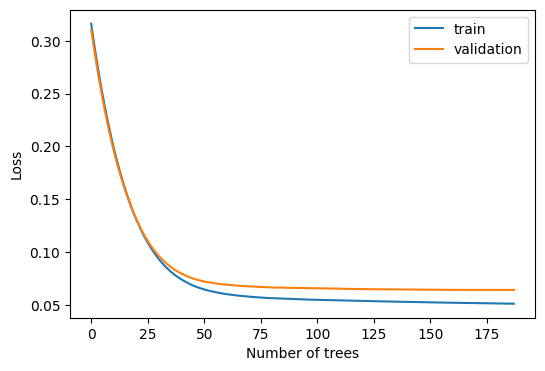

Test RMSE: 5.726772442908505



In [28]:
complete_Xgb("Model2_data", model_name ='xgb_m2')

## LSTM prediction function

In [29]:
# Function to perform predictions
def predict_training_validation_lstm(model, train_X1, train_y1, validation_X1, validation_y1):
    
    # Calculate RMSE for training data
    y_train_pred = model.predict(train_X1, verbose=0)
    rmse_train = calculate_rmse(y_train_pred, train_y1)
    print("Train RMSE: %.2f" % rmse_train)
    
    # Calculate RMSE for validation data
    y_val_pred = model.predict(validation_X1, verbose=0)
    rmse_val = calculate_rmse(y_val_pred, validation_y1)
    print("Validation RMSE: %.2f" % rmse_val)
    
    return rmse_train, rmse_val


def predict_without_lagged_values_lstm(X_test, Y_test, model):
    """
    Predicts the target variable without using lagged values for a given test dataset.

    Parameters:
        X_test (DataFrame): The input features of the test dataset.
        Y_test (array-like): The true target values of the test dataset.
        model: The trained model.

    Returns:
        predictions (array-like): The predicted target values.
        rmse (float): The root mean squared error between the true and predicted values (if Y_test is provided).
    """
    X_test = X_test.values  # Convert X_test to a NumPy array
    rmse = None
    instances = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])
    predictions = model.predict(instances, verbose=0)
        
    if Y_test is not None:
        rmse = calculate_rmse(predictions, Y_test)
        print("Test RMSE:", rmse)
        print()

    return predictions, rmse

def predict_with_lagged_values_lstm(X_test, Y_test, model, initial_values_for_test):
    predictions = []
    rmse = None

    initial_lag2_value = initial_values_for_test[0][0]
    initial_lag1_value = initial_values_for_test[1][0]

    existing_columns = X_test.columns.tolist()
    prev_y_lags = ['Y_Speed(t-1)', 'Y_Speed(t-2)']
    cols_w_y_lags = np.append(existing_columns, prev_y_lags)

    for i in range(len(X_test)):
        if i == 0:
            lag1_value = initial_lag1_value
            lag2_value = initial_lag2_value
        elif i == 1:
            lag1_value = predictions[i - 1]
            lag2_value = initial_lag1_value
        else:
            lag1_value = predictions[i - 1]
            lag2_value = predictions[i - 2]

        current_row = X_test.iloc[i].values
        input_data = np.concatenate([current_row, [lag1_value], [lag2_value]])
        #input_data_df = pd.DataFrame([input_data], columns=cols_w_y_lags)
        
        input_to_predict = input_data.reshape(1, 1, input_data.shape[0])
        prediction = model.predict(input_to_predict, verbose=0)
        predictions.append(prediction[0, 0]) # Access the predicted value from the prediction array

    predictions = np.array(predictions)  # Convert predictions to a NumPy array
    predictions = predictions.reshape(-1, 1)  # Reshape to a 2D array

    if Y_test is not None:
        rmse = calculate_rmse(predictions, Y_test)
        print("Test RMSE: ", rmse)
        print()

    return predictions, rmse

    
def reshape_data(x_data, y_data=None):
    """
    Reshape the input data arrays.

    Args:
        x_data (DataFrame): Input features data.
        y_data (DataFrame, optional): Target variable data. Defaults to None.

    Returns:
        tuple or ndarray: Reshaped x_data and y_data (if provided) as NumPy arrays.
    """
    # Convert DataFrames to NumPy arrays
    x_data = x_data.values        
    # Reshape x_data
    x_data = np.reshape(x_data, (x_data.shape[0], 1, x_data.shape[1]))
    
    if y_data is not None:
        y_data = y_data.values
        y_data = np.reshape(y_data, (y_data.shape[0], 1))
        
        return x_data, y_data
    
    else:
        return x_data


### LSTM Training/Tuning Functions

In [30]:
from sklearn.model_selection import TimeSeriesSplit
from kerastuner import Objective, RandomSearch
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense


#https://stackoverflow.com/questions/68503489/shaping-pandas-dataframe-for-lstm-input
def build_LSTM_model(hp,X_train):
    model = Sequential()
    model.add(
        LSTM(hp.Int('input_unit', min_value=64, max_value=256, step=64),
             return_sequences=True,
             input_shape=(X_train.shape[1], X_train.shape[2])))
    for i in range(hp.Int('n_layers', 1, 4)):
        model.add(
            LSTM(hp.Int(f'lstm_{i}_units',
                        min_value=64,
                        max_value=256,
                        step=64),
                 return_sequences=True))

    model.add(LSTM(6))
    if hp.Boolean("dropout"):
        model.add(
            Dropout(
                hp.Float('Dropout_rate', min_value=0, max_value=0.5,
                         step=0.1)))

    model.add(Dense(6))
    model.add(
        Dropout(hp.Float('Dropout_rate', min_value=0, max_value=0.5,
                         step=0.1)))

    model.add(Dense(1))
    model.compile(loss='mean_squared_error',
                  optimizer=tf.keras.optimizers.Adam(learning_rate=hp.Choice(
                      "learning_rate", values=[1e-2, 1e-3, 1e-4])),
                  metrics=['mse'])
    return model


def LSTM_HyperParam_Tuning(x_train, y_train, x_vali, y_vali, model_name,
                           tuned_model_file, retrain):
    
    x_train, y_train = reshape_data(x_train, y_train)
    x_vali, y_vali = reshape_data(x_vali, y_vali)
    
    tuner = RandomSearch(lambda hp: build_LSTM_model(hp, x_train),
                         objective='mse',
                         max_trials=15,
                         executions_per_trial=2,
                         overwrite=retrain,
                         directory=HYPER_PARAM_DIR,
                         project_name=model_name)

    stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss',
                                                  mode='min',
                                                  verbose=1,
                                                  patience=5)
    tuner.search(x=x_train,
                 y=y_train,
                 epochs=15,
                 batch_size=128,
                 validation_data=(x_vali, y_vali),
                 callbacks=[stop_early])
    
    best_model = tuner.get_best_models(num_models=1)[0]
    
    # Set the optimizer's variables to not be saved
    for var in best_model.optimizer.variables():
        var._trainable = False

    # Save the best model as an h5 file
    save_model_h5(best_model, tuned_model_file)

    # Retrieve the best model's hyperparameters
    best_params = tuner.get_best_hyperparameters(1)[0].values

    # Calculate RMSE on validation data using the best model
    val_predictions = best_model.predict(x_vali, verbose=0)
    val_rmse = calculate_rmse(val_predictions, y_vali)
    #print("Best Model Val RMSE ::",val_rmse)

    # Create a dictionary to store the results
    result_dict = {
        'Model Name': model_name,
        'Best Estimator': best_model,
        'Best Params': best_params,
        'Validation RMSE': val_rmse
    }
    
    results = {model_name: result_dict}
    
    # Write the best model's parameters to a file
    write_model_bestparam_to_file(results)
    
    return best_model


def plot_history_lstm(history1):
    # plot history
    plt.figure(figsize=(4,4))
    plt.plot(history1.history['loss'], label='train')
    plt.plot(history1.history['val_loss'], label='validation')
    plt.legend()
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.show()
    
def train_lstm(training_X, training_Y,validation_X, validation_Y,model, best_model_file):
    
    train_X1, train_y1 = reshape_data( training_X, training_Y)
    validation_X1, validation_y1 = reshape_data(validation_X, validation_Y)
    
    #Fit and plot loss history
    optimizer = tf.keras.optimizers.Adam()  # Replace with the optimizer you used during training
    loss = 'mse'  # Specify the same loss function you used during training
    model.compile(optimizer=optimizer, loss=loss, metrics=['mse'])
    
    stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss',
                                                  mode='min',
                                                  verbose=1,
                                                  patience=10)
    
    history = model.fit(train_X1, train_y1, validation_data=(validation_X1, validation_y1),
                        epochs=30, batch_size=128,callbacks=[stop_early])
    
    train_rmse ,val_rmse = predict_training_validation_lstm(model, train_X1, train_y1, 
                                                                   validation_X1, validation_y1)
    # Save the best model as an h5 file
    save_model_h5(model, best_model_file)
    
    return train_rmse ,val_rmse


In [31]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', message="Value in checkpoint could not be found in the restored object")
warnings.filterwarnings('ignore', message="Skipping variable loading for optimizer")


def call_tune_lstm(data_name, model_name):
    training_X, training_Y,validation_X, validation_Y,testing_X, testing_Y = read_data_dict(data_name)
    
    tuned_model_file = os.path.join(HYPER_PARAM_DIR, MODEL_NAMES[model_name])
    LSTM_HyperParam_Tuning(training_X, training_Y,validation_X, validation_Y, 
                                        model_name,tuned_model_file, True)


def complete_lstm(data_name, model_name):
    # Load the training, validation, and testing data
    training_X, training_Y, validation_X, validation_Y, testing_X, testing_Y = read_data_dict(data_name)

    # Load the tuned LSTM model
    tuned_model_file = os.path.join(HYPER_PARAM_DIR, MODEL_NAMES[model_name])
    tuned_model = load_model_h5(tuned_model_file)

    # Specify the file path to save the best model
    best_model_file = os.path.join(BEST_MODELS_DIR, MODEL_NAMES[model_name])

    # Train the tuned LSTM model with early stopping to avoid overfitting and save the best model 
    train_rmse, val_rmse = train_lstm(training_X, training_Y, validation_X, validation_Y, tuned_model, best_model_file)

    # Load the best trained LSTM model
    model = load_model_h5(best_model_file)

    # Make predictions on the testing data based on the data type
    if data_name == 'Model1_data' or data_name == 'Model2_data':
        # Predict without using lagged values
        predictions, rmse = predict_without_lagged_values_lstm(testing_X, testing_Y, model)
    else:
        # Extract initial speed values for testing
        initial_values_for_test = extract_initial_speed_for_test()
        # Predict using lagged values
        predictions, rmse = predict_with_lagged_values_lstm(testing_X, testing_Y, model, initial_values_for_test)

    # Inverse transform the predicted values
    predictions_transformed = inverse_transform_y_predicted(predictions)

    # Create a dictionary with the model name and evaluation metrics
    result_dict = {
        'Model Name': model_name,
        'Training RMSE': train_rmse,
        'Validation RMSE': val_rmse,
        'Testing RMSE': rmse
    }

    # Store the results dictionary in a larger dictionary
    results = {model_name: result_dict}

    # Write the model predictions and RMSE to a file
    write_model_predictions_rmse_to_file(results, predictions_transformed)

    


### Tune LSTM

In [32]:
call_tune_lstm("Model2_data", model_name ='lstm_m2')

Trial 15 Complete [00h 02m 17s]
mse: 0.050254520028829575

Best mse So Far: 0.0028266985900700092
Total elapsed time: 00h 27m 42s
INFO:tensorflow:Oracle triggered exit
Model successfully saved to 'b_PIE_hyperparam\lstm_m2.h5'.


### Train LSTM

In [33]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2' 
complete_lstm("Model2_data", model_name ='lstm_m2')

Model successfully loaded from 'b_PIE_hyperparam\lstm_m2.h5'.
Epoch 1/30
76/76 [==============================] - 17s 63ms/step - loss: 0.0024 - mse: 0.0024 - val_loss: 0.0048 - val_mse: 0.0048
Epoch 2/30
76/76 [==============================] - 2s 21ms/step - loss: 0.0024 - mse: 0.0024 - val_loss: 0.0043 - val_mse: 0.0043
Epoch 3/30
76/76 [==============================] - 2s 22ms/step - loss: 0.0023 - mse: 0.0023 - val_loss: 0.0049 - val_mse: 0.0049
Epoch 4/30
76/76 [==============================] - 2s 21ms/step - loss: 0.0023 - mse: 0.0023 - val_loss: 0.0044 - val_mse: 0.0044
Epoch 5/30
76/76 [==============================] - 2s 21ms/step - loss: 0.0023 - mse: 0.0023 - val_loss: 0.0051 - val_mse: 0.0051
Epoch 6/30
76/76 [==============================] - 2s 21ms/step - loss: 0.0023 - mse: 0.0023 - val_loss: 0.0049 - val_mse: 0.0049
Epoch 7/30
76/76 [==============================] - 2s 21ms/step - loss: 0.0023 - mse: 0.0023 - val_loss: 0.0045 - val_mse: 0.0045
Epoch 8/30
76/76 [==

## Model MSE summary

In [34]:
model_error_df = pd.read_csv(os.path.join(BEST_MODELS_DIR, MODELS_RMSE_FILE))
model_error_df

,Model Name,Training RMSE,Validation RMSE,Testing RMSE
0,svr_m1,6.408806,7.456357,6.764132
1,svr_m2,6.206990,6.894401,6.378206
2,svr_m3,3.567757,3.966025,9.361318
3,svr_m4,3.606734,3.997633,8.029913
4,xgb_m1,3.469516,5.639894,5.609974
5,xgb_m2,4.471648,5.466523,5.726772
6,xgb_m3,2.778554,3.408710,7.398407
7,xgb_m4,2.375279,3.386239,6.850327
8,lstm_m1,4.617920,6.235497,5.832628
9,lstm_m2,4.234593,5.959244,5.769009


### Feature Importance

[12:32:06] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:553: 
  If you are loading a serialized model (like pickle in Python, RDS in R) generated by
  older XGBoost, please export the model by calling `Booster.save_model` from that version
  first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/latest/tutorials/saving_model.html

  for more details about differences between saving model and serializing.

xgb_m1


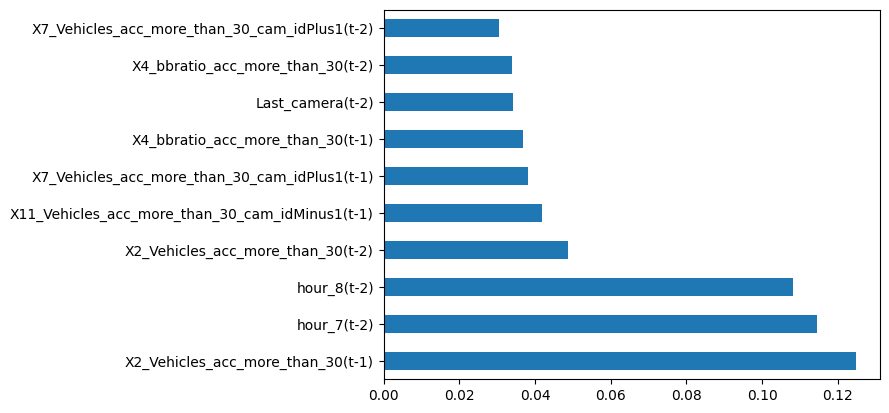

                                            columns  importances  rank
35                X2_Vehicles_acc_more_than_30(t-1)     0.124814     1
18                                      hour_7(t-2)     0.114588     2
19                                      hour_8(t-2)     0.108288     3
0                 X2_Vehicles_acc_more_than_30(t-2)     0.048806     4
39  X11_Vehicles_acc_more_than_30_cam_idMinus1(t-1)     0.041729     5
37    X7_Vehicles_acc_more_than_30_cam_idPlus1(t-1)     0.038115     6
36                 X4_bbratio_acc_more_than_30(t-1)     0.036918     7
7                                  Last_camera(t-2)     0.034204     8
1                  X4_bbratio_acc_more_than_30(t-2)     0.033965     9
2     X7_Vehicles_acc_more_than_30_cam_idPlus1(t-2)     0.030599    10
xgb_m2


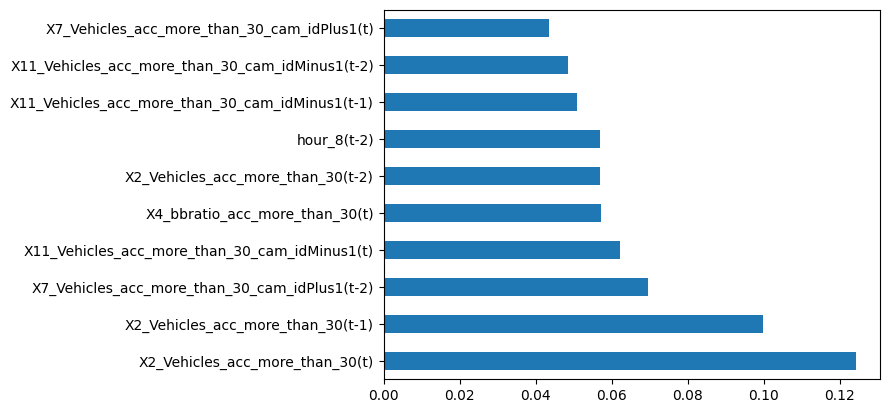

                                            columns  importances  rank
41                  X2_Vehicles_acc_more_than_30(t)     0.124224     1
35                X2_Vehicles_acc_more_than_30(t-1)     0.099894     2
2     X7_Vehicles_acc_more_than_30_cam_idPlus1(t-2)     0.069559     3
45    X11_Vehicles_acc_more_than_30_cam_idMinus1(t)     0.062161     4
42                   X4_bbratio_acc_more_than_30(t)     0.057132     5
0                 X2_Vehicles_acc_more_than_30(t-2)     0.056923     6
19                                      hour_8(t-2)     0.056896     7
39  X11_Vehicles_acc_more_than_30_cam_idMinus1(t-1)     0.050970     8
4   X11_Vehicles_acc_more_than_30_cam_idMinus1(t-2)     0.048583     9
43      X7_Vehicles_acc_more_than_30_cam_idPlus1(t)     0.043422    10
[12:32:07] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:553: 
  If you are loading a serialized model (like pickle in Python,

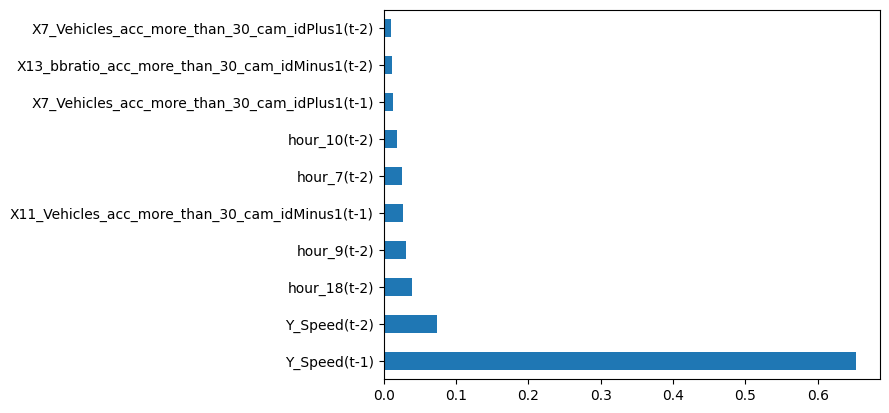

                                            columns  importances  rank
41                                     Y_Speed(t-1)     0.652689     1
42                                     Y_Speed(t-2)     0.074210     2
29                                     hour_18(t-2)     0.039333     3
20                                      hour_9(t-2)     0.031064     4
39  X11_Vehicles_acc_more_than_30_cam_idMinus1(t-1)     0.026813     5
18                                      hour_7(t-2)     0.025310     6
21                                     hour_10(t-2)     0.018463     7
37    X7_Vehicles_acc_more_than_30_cam_idPlus1(t-1)     0.013580     8
5    X13_bbratio_acc_more_than_30_cam_idMinus1(t-2)     0.011361     9
2     X7_Vehicles_acc_more_than_30_cam_idPlus1(t-2)     0.010322    10
[12:32:07] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:553: 
  If you are loading a serialized model (like pickle in Python,

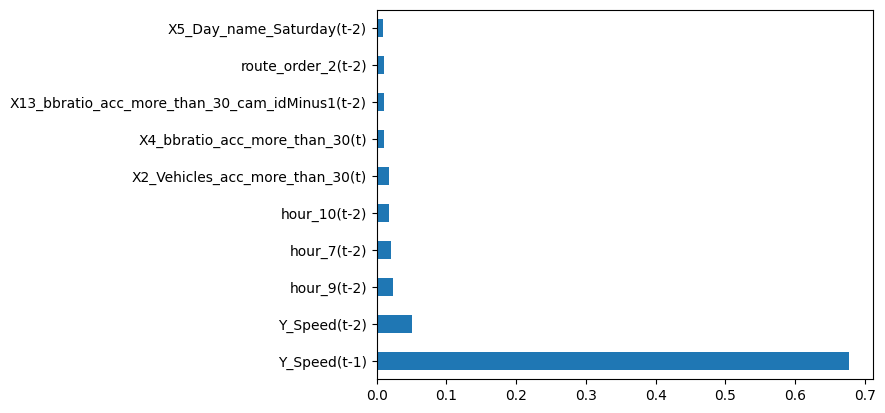

                                           columns  importances  rank
47                                    Y_Speed(t-1)     0.677302     1
48                                    Y_Speed(t-2)     0.051170     2
20                                     hour_9(t-2)     0.022811     3
18                                     hour_7(t-2)     0.020567     4
21                                    hour_10(t-2)     0.018169     5
41                 X2_Vehicles_acc_more_than_30(t)     0.017584     6
42                  X4_bbratio_acc_more_than_30(t)     0.010632     7
5   X13_bbratio_acc_more_than_30_cam_idMinus1(t-2)     0.010380     8
14                              route_order_2(t-2)     0.009911     9
10                       X5_Day_name_Saturday(t-2)     0.009660    10


,X_cols,if_xgb_m1_cols,xgb_m1_feature_rank,if_xgb_m2_cols,xgb_m2_feature_rank,if_xgb_m3_cols,xgb_m3_feature_rank,if_xgb_m4_cols,xgb_m4_feature_rank
0,X2_Vehicles_acc_more_than_30(t-2),True,4,True,6,True,,True,
1,X4_bbratio_acc_more_than_30(t-2),True,9,True,,True,,True,
2,X7_Vehicles_acc_more_than_30_cam_idPlus1(t-2),True,10,True,3,True,10,True,
3,X9_bbratio_acc_more_than_30_cam_idPlus1(t-2),True,,True,,True,,True,
4,X11_Vehicles_acc_more_than_30_cam_idMinus1(t-2),True,,True,9,True,,True,
5,X13_bbratio_acc_more_than_30_cam_idMinus1(t-2),True,,True,,True,9,True,8
6,First_camera(t-2),True,,True,,True,,True,
7,Last_camera(t-2),True,8,True,,True,,True,
8,X5_Day_name_Friday(t-2),True,,True,,True,,True,
9,X5_Day_name_Monday(t-2),True,,True,,True,,True,


In [35]:
def find_importance(feature_cols, model_name):
    best_model_file = os.path.join(BEST_MODELS_DIR, MODEL_NAMES[model_name])
    xgb_model =  read_pickle(best_model_file)
    
    feat_importances = pd.Series(xgb_model.feature_importances_, index=feature_cols)
    print(model_name)
    feat_importances.nlargest(10).plot(kind='barh')
    plt.show() 

    results = pd.DataFrame()
    results['columns'] = feature_cols
    results['importances'] = xgb_model.feature_importances_
    results.sort_values(by='importances', ascending=False, inplace=True)
    results['rank'] = range(1, len(results) + 1)  # Add rank column
    
    print(results[:10])
    
    return results


#Get the model imporance for all the xgb models
model_data_list = ["Model2_data"]
xgb_model_name_list = ["xgb_m2"]

training_X, training_Y,validation_X, validation_Y,testing_X, testing_Y = read_data_dict("Model4_data")
total_X_cols =  training_X.columns.tolist()

feat_imp_df = pd.DataFrame()
feat_imp_df['X_cols'] = total_X_cols

for i in range(len(model_data_list)):
    training_X, training_Y,validation_X, validation_Y,testing_X, testing_Y = read_data_dict(model_data_list[i])
    model_x_cols = training_X.columns.tolist()

        
    results = find_importance(model_x_cols, xgb_model_name_list[i])
    
    # we are creation a binary column to specify the presence of a column
    feat_imp_df["if_"+xgb_model_name_list[i]+"_cols"] =  list(map(lambda x: x in model_x_cols, total_X_cols))
    
    ranked_columns = []
    for column in total_X_cols:
        if column in results['columns'].values:
            rank = results.loc[results['columns'] == column, 'rank'].values[0]
            if(rank<11):
                ranked_columns.append(rank)
            else:
                ranked_columns.append('')
        else:
            ranked_columns.append('')
    
    # we are creating a column to specify rank of the column for the model
    feat_imp_df[xgb_model_name_list[i]+"_feature_rank"]  = ranked_columns    
    
feat_imp_df.to_csv(ROUTE+'_feature_importance.csv', index=False)
feat_imp_df  

## Predict speed for unknown

In [36]:
UNSEEN_DATA_FOLDER = "test_data_unseen"

DATA_MODEL_MAPPING = {
                 'Model2_data':['lstm_m2', 'xgb_m2', 'svr_m2']}

def convert_timeseries_to_supervised_for_unseen_data(df_X, incl_curr_X=True, lag_steps=2, dropnan=True):
    # Initialize lists to store values and column names
    col_values, col_names, = [], []

    def append_shifted_values(df, columns, shift_amount):
        # Append shifted values of df for selected columns
        col_values.append(df.shift(shift_amount)[columns])
        col_names.extend(['%s(t-%d)' % (col, shift_amount) for col in columns])

    # input sequence (t-n(lag_steps), ... t-1)
    if not incl_curr_X:  
        for i in range(lag_steps, 0, -1):
            if i == lag_steps:
                # For the first lag step, append shifted values of df_X for X_COLS
                append_shifted_values(df_X, X_COLS, i)
            else:
                # For subsequent lag steps, append shifted values of df_X for SELECTED_X_COLS_FOR_ALL_LAGS
                append_shifted_values(df_X, SELECTED_X_COLS_FOR_ALL_LAGS, i)
            

    # input sequence (t-n(lag_steps), ... t)
    if incl_curr_X:  
        for i in range(lag_steps, -1, -1):
            
            if i == lag_steps:
                # For the first lag step, append shifted values of df_X for X_COLS
                append_shifted_values(df_X, X_COLS, i)

            elif i == 0:
                # Handle i = 0 differently
                col_values.append(df_X[SELECTED_X_COLS_FOR_ALL_LAGS])  # Use current values instead of shifted values
                col_names.extend(['%s(t)' % col for col in SELECTED_X_COLS_FOR_ALL_LAGS])
                
            else:
                # For subsequent lag steps, append shifted values of df_X for SELECTED_X_COLS_FOR_ALL_LAGS
                append_shifted_values(df_X, SELECTED_X_COLS_FOR_ALL_LAGS, i)
   
    # Concatenate the lagged values and assign column names
    agg = pd.concat(col_values, axis=1)
    agg.columns = col_names
    
    # Drop the first lag_steps rows as they contain NaN values
    agg = agg.iloc[lag_steps:]
    
    # Drop rows with NaN values if specified
    if dropnan:
        agg.dropna(inplace=True)
    
    return agg

# write speed to file
def write_predicted_output(prediction_dic,new_data_df):
    
    prediction_dic_formatted = {key: np.array(value).flatten().tolist() for key, value in prediction_dic.items()}
    output_df = pd.DataFrame.from_dict(prediction_dic_formatted)
    time_values = new_data_df['Timestamp'][2:].tolist() 

    for i in range(len(time_values)):
        output_df.loc[i, 'Timestamp'] = time_values[i]

    # Reorder the columns with 'Timestamp' as the first column
    columns = ['Timestamp'] + [col for col in output_df.columns if col != 'Timestamp']
    output_df = output_df[columns]

    output_df.to_csv(os.path.join(UNSEEN_DATA_FOLDER, OUTPUT_CSV),index=False)

    
# write speed to file with allinput cols
def write_predicted_output_full(FILE_TO_READ,OUTPUT_CSV):
    # write predicted output to file
    read_df2 = pd.read_csv(FILE_TO_READ)
    read_df2  = read_df2.loc[(read_df2['Route'].isin(ROUTE_LIST))]
    read_df2['Timestamp'] = pd.to_datetime(read_df2['Timestamp']) 

    read_df2.reset_index(drop=True, inplace=True)
    read_df2 = read_df2.loc[2:,]
    read_df2.reset_index(drop=True, inplace=True)
    
    output_df= pd.read_csv(OUTPUT_CSV)
    output_df.reset_index(drop=True, inplace=True)

    combined_output = pd.concat([read_df2, output_df], axis=1) 
    combined_output.to_csv(os.path.join(UNSEEN_DATA_FOLDER,OUTPUT_FULL),index=False)

In [37]:
# Read the file and store the data in a dataframe
def predict_speed_unseen_data(FILE_TO_READ,OUTPUT_CSV):
    new_data_df = read_file(FILE_TO_READ)

    # Preprocess the test data
    test_X_unseen, Y = preprocess_test_data(new_data_df)
    
    # Prepare data dictionary for unseen data 
    data_dict_for_unseen = {}
    def prepare_data_dict_for_unseen_data(test_X_unseen, curr_x, data_name):
        data_dict_for_unseen[data_name] = convert_timeseries_to_supervised_for_unseen_data(test_X_unseen,  incl_curr_X=curr_x)

    #with curr_x=True for Model2_data
    prepare_data_dict_for_unseen_data(test_X_unseen, curr_x=True, data_name="Model2_data")

    # Create a dictionary to store predictions for each model
    prediction_dic = {}

    # Iterate over the keys in DATA_MODEL_MAPPING
    for key in DATA_MODEL_MAPPING.keys():
        data_name = key

        testing_X = data_dict_for_unseen[data_name]
        testing_Y = None

        model_list = DATA_MODEL_MAPPING[key]

        # Iterate over the model names in the model_list
        for model_name in model_list:
            if model_name.startswith("lstm"):
                # Load the best LSTM model from file
                best_model_file = os.path.join(BEST_MODELS_DIR, MODEL_NAMES[model_name]) 
                model = load_model_h5(best_model_file)

                if data_name == 'Model1_data' or data_name == 'Model2_data':
                    # Make predictions without using lagged values for Model1_data and Model2_data
                    predictions, rmse = predict_without_lagged_values_lstm(testing_X, testing_Y, model)

                else:
                    # Extract initial values for test data
                    initial_values_for_test = extract_initial_speed_for_test()
                    # Make predictions using lagged values for Model3_data and Model4_data
                    predictions, rmse = predict_with_lagged_values_lstm(testing_X, testing_Y, model, initial_values_for_test)

            else:
                # Load the best ML model from file
                best_model_file = os.path.join(BEST_MODELS_DIR, MODEL_NAMES[model_name]) 
                model = read_pickle(best_model_file)

                if data_name == 'Model1_data' or data_name == 'Model2_data':
                    # Make predictions without using lagged values for Model1_data and Model2_data
                    predictions, rmse = predict_without_lagged_values_ml(testing_X, testing_Y, model)

                else:
                    # Extract initial values for test data
                    initial_values_for_test = extract_initial_speed_for_test()
                    # Make predictions using lagged values for Model3_data and Model4_data
                    predictions, rmse = predict_with_lagged_values_ml(testing_X, testing_Y, model, initial_values_for_test)

            # Scale the predictions back to the original range
            predictions_scaled = inverse_transform_y_predicted(predictions)
            # Store the scaled predictions in the prediction dictionary
            prediction_dic[model_name] = predictions_scaled
            
    write_predicted_output(prediction_dic,new_data_df)
    

## Random Forest code

In [38]:
from sklearn.ensemble import RandomForestRegressor

def rf_hyperParameterTuning(X_train, y_train, X_val, y_val, model_name, tuned_model_file):
    """
    Performs hyperparameter tuning for Random Forest using randomized search and cross-validation.

    Parameters:
        X_train: Training features.
        y_train: Training target values.
        X_val: Validation features.
        y_val: Validation target values.
        model_name: Name of the model.
        tuned_model_file: File path to save the tuned model.

    Returns:
        best_params: Best set of hyperparameters found during tuning.
        best_val_rmse: Root mean squared error (RMSE) of the best model on the validation dataset.
    """
    # Define the hyperparameter grid for tuning
    param_tuning = {
        'n_estimators': [50, 100, 200, 500, 1000],
        'max_depth': [3, 5, 7, 9, 11],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'bootstrap': [True, False]
    }

    # Create a Random Forest regressor model
    rf_model = RandomForestRegressor(random_state=42)

    # Perform randomized search with cross-validation
    tscv = TimeSeriesSplit(n_splits=2)
    rsearch = RandomizedSearchCV(estimator=rf_model,
                                 param_distributions=param_tuning, cv=tscv, n_jobs=-1, verbose=2)
    rsearch.fit(X_train, y_train)

    # Retrieve the best model, best parameters, and the corresponding validation RMSE
    best_model = rsearch.best_estimator_
    best_params = rsearch.best_params_
    
    val_predictions = best_model.predict(X_val)  # Predict on validation data
    val_predictions = val_predictions.reshape(-1, 1)  # Reshape predictions to a 2D array
    val_rmse = calculate_rmse(val_predictions, y_val)  # Calculate RMSE on validation data

    # Create a dictionary with the model name, best estimator, best parameters, and validation RMSE
    result_dict = {
        'Model Name': model_name,
        'Best Estimator': best_model,
        'Best Params': best_params,
        'Validation RMSE': val_rmse
    }

    # Display the results of the best model and its parameters
    print(f"Best Model Params: {best_params}")
    print(f"Best Model Val RMSE: {val_rmse:.3f}")
    print()

    # Store the result dictionary in a larger dictionary with the model name as the key
    results = {model_name: result_dict}

    # Write the result dictionary to a file
    write_model_bestparam_to_file(results)

    # Save the best model as a pickle file
    write_pickle(best_model, tuned_model_file)

    # Return the best parameters and validation RMSE
    return best_params, val_rmse


from sklearn.metrics import mean_squared_error
def train_rf(train_X, train_y, validation_X, validation_y, model, best_model_file):
    """
    Train a Random Forest model with early stopping and compute RMSE for training and validation data.

    Parameters:
        train_X: Training features.
        train_y: Training target values.
        validation_X: Validation features.
        validation_y: Validation target values.
        model: Random Forest model instance.
        best_model_file: File path to save the best model.

    Returns:
        train_rmse: Root mean squared error (RMSE) for training data.
        validation_rmse: RMSE for validation data.
    """
    # Train the model
    model.fit(train_X, train_y)
    
    # Save the best model as a pickle file
    write_pickle(model, best_model_file)
    
    # Predict on training and validation data
    train_predictions = model.predict(train_X)
    validation_predictions = model.predict(validation_X)
    
    # Compute RMSE for training and validation data
    train_rmse, validation_rmse = predict_training_validation_ml(model, train_X, train_y, validation_X, validation_y)
    
    # Plot feature importances
    feature_cols = train_X.columns.tolist()
    feat_importances = pd.Series(model.feature_importances_, index=feature_cols)
    feat_importances.nlargest(10).plot(kind='barh')
    plt.show()
    
    return train_rmse, validation_rmse

In [39]:
def call_tune_rf(data_name, model_name):
    training_X, training_Y,validation_X, validation_Y,testing_X, testing_Y = read_data_dict(data_name)
        
    tuned_model_file = os.path.join(HYPER_PARAM_DIR, MODEL_NAMES[model_name])     
    rf_hyperParameterTuning(training_X, training_Y,validation_X, validation_Y, model_name,tuned_model_file)

    
def complete_rf(data_name, model_name):
    # Load the training, validation, and testing data
    training_X, training_Y, validation_X, validation_Y, testing_X, testing_Y = read_data_dict(data_name)
    
    # Load the tuned XGBoost model
    tuned_model_file = os.path.join(HYPER_PARAM_DIR, MODEL_NAMES[model_name])
    tuned_model = read_pickle(tuned_model_file)
    
    # Specify the file path to save the best model
    best_model_file = os.path.join(BEST_MODELS_DIR, MODEL_NAMES[model_name])
    
    # Train the tuned XGBoost model and save the best model
    train_rmse, val_rmse = train_rf(training_X, training_Y, validation_X, validation_Y, tuned_model, best_model_file)
    
    # Load the best trained XGBoost model
    model = read_pickle(best_model_file)
                         
    # Test the model on unseen data based on the data type
    if data_name == 'Model1_data' or data_name == 'Model2_data':
        # Predict without using lagged values
        predictions, rmse = predict_without_lagged_values_ml(testing_X, testing_Y, model)
        
    else:
        # Extract initial speed values for testing
        initial_values_for_test = extract_initial_speed_for_test()
        # Predict using lagged values
        predictions, rmse = predict_with_lagged_values_ml(testing_X, testing_Y, model, initial_values_for_test)
    
        
    # Denormalize the predicted results
    predictions_transformed = inverse_transform_y_predicted(predictions)    
    result_dict = {
        'Model Name': model_name,
        'Training RMSE': train_rmse,
        'Validation RMSE': val_rmse,
        'Testing RMSE': rmse
    }
    
    results = {model_name: result_dict}
    write_model_predictions_rmse_to_file(results, predictions_transformed)

### Tune RF

In [40]:
call_tune_rf("Model2_data", model_name ='rf_m2')

Fitting 2 folds for each of 10 candidates, totalling 20 fits
Best Model Params: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 9, 'bootstrap': True}
Best Model Val RMSE: 5.443

Data successfully written to 'b_PIE_hyperparam\rf_m2.pkl'.


### Train RF

Data successfully written to 'b_PIE_best_models\rf_m2.pkl'.
Train RMSE: 3.81
Validation RMSE: 5.44


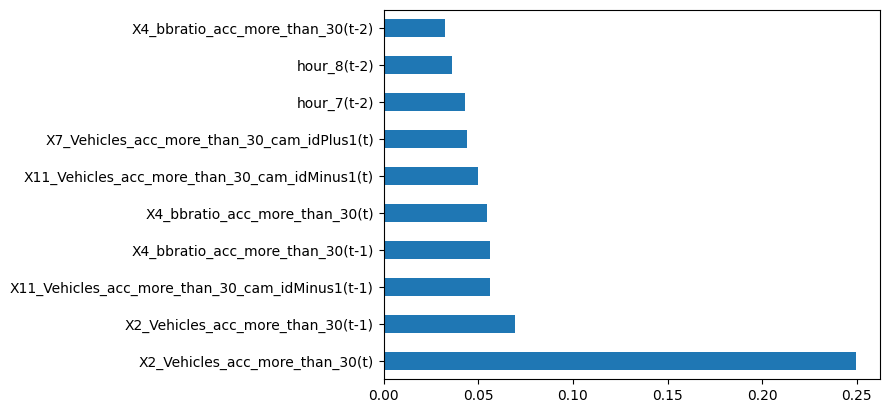

Test RMSE: 5.679645517613016



In [41]:
complete_rf("Model2_data", model_name ='rf_m2')

## predict for lags y

In [42]:
prepare_data_dict_for_model(curr_x=True, prev_y=False, data_name="Model2_data",plus_value=1)
training_X, training_Y,validation_X, validation_Y,testing_X, testing_Y = read_data_dict("Model2_data")

Fitting 2 folds for each of 10 candidates, totalling 20 fits
Best Model Params: {'objective': 'reg:squarederror', 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05}
Best Model Val RMSE: 5.846

Data successfully written to 'b_PIE_hyperparam\xgb_m2_1.pkl'.
Data successfully written to 'b_PIE_best_models\xgb_m2_1.pkl'.
Train RMSE: 4.89
Validation RMSE: 5.85


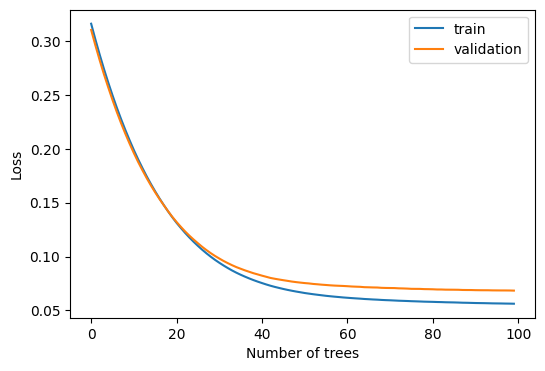

Test RMSE: 6.0240536025234475



In [43]:
call_tune_xgb("Model2_data", model_name ='xgb_m2_1')
complete_Xgb("Model2_data", model_name ='xgb_m2_1')

In [44]:
call_tune_lstm("Model2_data", model_name ='lstm_m2_1')
complete_lstm("Model2_data", model_name ='lstm_m2_1')

Trial 12 Complete [00h 01m 15s]
mse: 0.006170096807181835

Best mse So Far: 0.0029436959885060787
Total elapsed time: 00h 21m 44s

Search: Running Trial #13

Value             |Best Value So Far |Hyperparameter
128               |192               |input_unit
4                 |2                 |n_layers
64                |256               |lstm_0_units
False             |True              |dropout
0.4               |0                 |Dropout_rate
0.01              |0.01              |learning_rate
128               |64                |lstm_1_units
64                |256               |lstm_2_units
192               |128               |lstm_3_units

Epoch 1/15
76/76 [==============================] - 16s 68ms/step - loss: 0.0934 - mse: 0.0934 - val_loss: 0.0074 - val_mse: 0.0074
Epoch 2/15
76/76 [==============================] - 3s 35ms/step - loss: 0.0241 - mse: 0.0241 - val_loss: 0.0047 - val_mse: 0.0047
Epoch 3/15
76/76 [==============================] - 3s 35ms/step - loss: 0.0

In [45]:
prepare_data_dict_for_model(curr_x=True, prev_y=False, data_name="Model2_data",plus_value=3)
training_X, training_Y,validation_X, validation_Y,testing_X, testing_Y = read_data_dict("Model2_data")

In [46]:
call_tune_xgb("Model2_data", model_name ='xgb_m2_3')
complete_Xgb("Model2_data", model_name ='xgb_m2_3')

In [47]:
call_tune_lstm("Model2_data", model_name ='lstm_m2_3')
complete_lstm("Model2_data", model_name ='lstm_m2_3')

In [48]:
prepare_data_dict_for_model(curr_x=True, prev_y=False, data_name="Model2_data",plus_value=6)
training_X, training_Y,validation_X, validation_Y,testing_X, testing_Y = read_data_dict("Model2_data")

In [49]:
call_tune_xgb("Model2_data", model_name ='xgb_m2_6')
complete_Xgb("Model2_data", model_name ='xgb_m2_6')

In [50]:
call_tune_lstm("Model2_data", model_name ='lstm_m2_6')
complete_lstm("Model2_data", model_name ='lstm_m2_6')

In [51]:
res_df = pd.read_csv(TEST_SPEED_RESULT_FILE)

res_df['m2_1_org'] = res_df['Y_Speed'].shift(-1)
res_df['lstm_m2_1_diff'] = res_df['m2_1_org'] - res_df['lstm_m2_1']
res_df['xgb_m2_1_diff'] = res_df['m2_1_org'] - res_df['xgb_m2_1']

res_df['m2_3_org'] =  res_df['Y_Speed'].shift(-3)
res_df['lstm_m2_3_diff'] = res_df['m2_3_org'] - res_df['lstm_m2_3']
res_df['xgb_m2_3_diff'] = res_df['m2_3_org'] - res_df['xgb_m2_3']

res_df['m2_6_org'] =  res_df['Y_Speed'].shift(-6)
res_df['lstm_m2_6_diff'] = res_df['m2_6_org'] - res_df['lstm_m2_6']
res_df['xgb_m2_6_diff'] = res_df['m2_6_org'] - res_df['xgb_m2_6']

file_name = ROUTE+'_rcnn.csv'
res_df.to_csv(file_name, index=False)

res_df.tail(8)

In [52]:
import matplotlib.pyplot as plt

# Specify the columns to plot
columns_to_plot = ['xgb_m2_6_diff', 'xgb_m2_3_diff', 'xgb_m2_1_diff','lstm_m2_6_diff', 'lstm_m2_3_diff', 'lstm_m2_1_diff']

# Create the box plot
res_df[columns_to_plot].boxplot(figsize=(10, 6))

# Add title and labels
plt.title('Box plots for m2_6_diff, m2_3_diff, and m2_1_diff')
plt.ylabel('Values')

plt.ylim(-80, 80)

# Show the plot
plt.show()

In [53]:
import matplotlib.pyplot as plt

# Specify the columns to plot
columns_to_plot = ['lstm_m2_6_diff', 'lstm_m2_3_diff', 'lstm_m2_1_diff']

# Create the box plot
res_df[columns_to_plot].boxplot()

# Add title and labels
plt.title('Box plots for lstm_m2_6_diff, lstm_m2_3_diff, and lstm_m2_1_diff')
plt.ylabel('Values')
plt.xlabel('Features')

# Show the plot
plt.show()


### ML Flow configuration